In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.neighbors import KNeighborsRegressor




In [8]:
df = pd.read_csv("robot_parts_data.csv")
X, y = df[["weight_g", "length_mm"]], df["part"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [4]:
X_test.head()

,weight_g,length_mm
73,4.7,26.8
18,2.6,21.0
118,4.7,16.5
78,7.6,31.4
76,6.0,11.9


In [11]:
y_test.head()

73       bolt
18     washer
118       nut
78       bolt
76        nut
Name: part, dtype: str

In [9]:
model = make_pipeline(StandardScaler(),
                      KNeighborsClassifier(n_neighbors=5))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(y_pred)
print("Accuracy:", round(metrics.accuracy_score(y_test, y_pred), 2))
print("F1 (macro):", round(metrics.f1_score(y_test, y_pred,
                                            average="macro"), 2))



['washer' 'washer' 'washer' 'bolt' 'nut' 'bolt' 'washer' 'nut' 'nut'
 'washer' 'nut' 'bolt' 'washer' 'bolt' 'washer' 'nut' 'washer' 'bolt'
 'washer' 'washer' 'washer' 'nut' 'bolt' 'nut' 'nut' 'nut' 'washer' 'bolt'
 'washer' 'washer']
Accuracy: 0.77
F1 (macro): 0.76


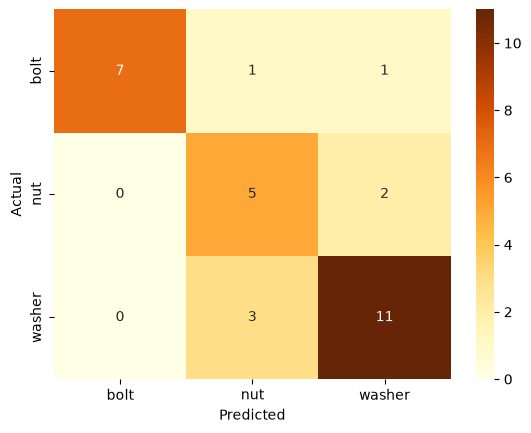

In [7]:
names = model.classes_
cm = metrics.confusion_matrix(y_test, y_pred, labels=names)
sns.heatmap(cm, annot=True, cmap="YlOrBr",
            xticklabels=names, yticklabels=names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

In [14]:
df1 = pd.read_csv("robot_braking_data.csv")
X = df1[["speed_mps"]]
y = df1["stopping_distance_m"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



In [12]:
df1.head()

,speed_mps,stopping_distance_m
0,0.21,0.02
1,0.22,0.04
2,0.24,0.04
3,0.34,0.02
4,0.37,0.07


In [21]:
model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
model.fit(X_train, y_train)
y_pred = model.predict([[0.6]])

c:\Users\Lavan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [22]:
print("Predicted Braking Distances:", y_pred)

Predicted Braking Distances: [0.242]
